In [1]:
import pandas
from matplotlib import pyplot

In [2]:
all = pandas.read_csv('all_participants.csv')
all

,age,hours_per_week,mmol_per_l
0,16.000000,5.843125,14.113629
1,16.054054,5.676110,14.327836
2,16.108108,5.625638,14.398265
3,16.162162,5.745338,14.258370
4,16.216216,5.646665,14.388450
...,...,...,...
995,69.735797,8.349634,17.193744
996,69.790554,8.542945,16.827537
997,69.845311,8.699154,16.532565
998,69.897331,8.594576,16.740140


## Ejercicio 3

> Nuestros epidemiólogos sospechan que la gente suele hacer más ejercicio físico a medida que se hacen más mayores y responsables.
>

**1. ¿Puedes crear una visualización para aclarar la relación entre la edad y ejercicio físico por semana?**

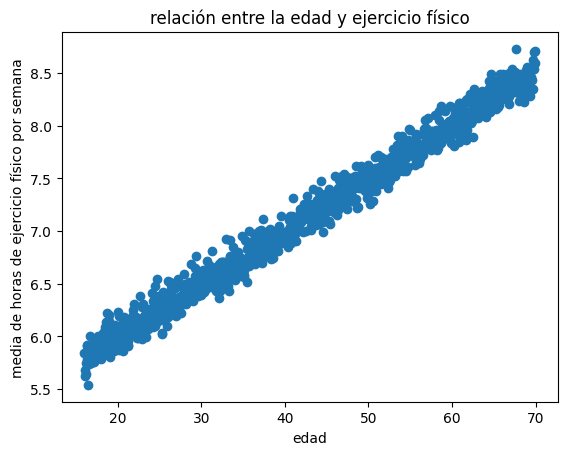

In [3]:
f, ax = pyplot.subplots()
ax.set_title("relación entre la edad y ejercicio físico")
ax.set_xlabel('edad')
ax.set_ylabel('media de horas de ejercicio físico por semana')
ax.plot(all['age'], all['hours_per_week'], 'o')

**2. ¿Qué tipo de relación observas entre la edad y el ejercicio físico?**

Los datos indican que la gente con más edad hace más ejercicio que la gente con menos edad.

## Ejercicio 4

> La Dra. Sánchez está tremendamente excitada porque cree haber descubierto una relación importantísima entre la cantidad de ejercicio y el thanatol en sangre.
>
> Quiere:
> 
> - publicar un paper en Nature exponiendo la asociación positiva entre ejercicio y thanatol en sangre
> - recomendar a todos sus pacientes que dejen de hacer ejercicio inmediatamente
> 
> Pero la Dra. Sánchez es una científica responsable así que antes quiere que le eches un vistazo a los datos para confirmar:
> 

**1. ¿Puedes crear una visualización para aclarar la relación entre ejercicio físico por semana y nivel de thanatol en sangre?**

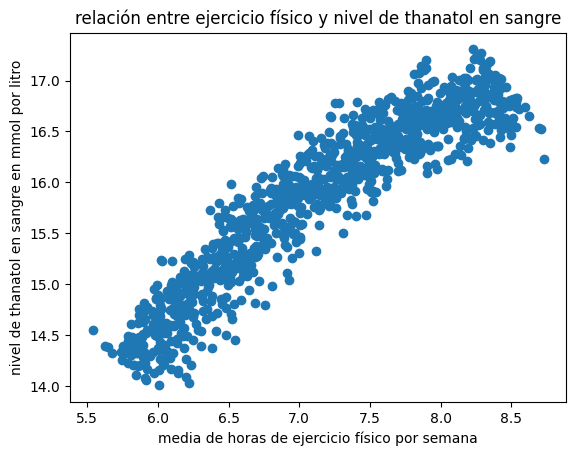

In [4]:
f, ax = pyplot.subplots()
ax.set_title("relación entre ejercicio físico y nivel de thanatol en sangre")
ax.set_xlabel('media de horas de ejercicio físico por semana')
ax.set_ylabel('nivel de thanatol en sangre en mmol por litro')
ax.plot(all['hours_per_week'], all['mmol_per_l'], 'o')

**2. ¿Estás de acuerdo con la Dra. Sánchez que hay una correlación fuerte positiva entre ejercicio físico y nivel de thanatol en sangre?**

No del todo. Motivos:
- Observando la gráfica anterior se pueden ver ejemplos que contradicen la Dra. Sánchez, eg:
    - hay casos donde con ~6h de ejercicio el paciente tiene ~15.5mmol de thanatol
    - hay casos donde con ~6,5h de ejercicio el paciente tiene ~14.5mmol de thanatol
- El [Pearson correlation coefficient](https://en.wikipedia.org/wiki/Pearson_correlation_coefficient) entre las dos variables `hours_per_week` y `mmol_per_l` es `0.9304`. Si fuese `1` entonces probablemente la Dra. Sánchez tendría razón.


In [5]:
all.corr(method='pearson')

,age,hours_per_week,mmol_per_l
age,1.000000,0.991771,0.964055
hours_per_week,0.991771,1.000000,0.930411
mmol_per_l,0.964055,0.930411,1.000000


**3. ¿Crees que es buena idea recomendar a los pacientes de la Dra. Sánchez que dejen de hacer ejercicio inmediatamente?**

No, porque no sabemos si realmente es la cantidad de ejercicio la que causa que el nivel de thanatol aumente: https://en.wikipedia.org/wiki/Correlation_does_not_imply_causation

## Ejercicio 5

> La Dra. Simpson es pediatra, y ha estado fijándose en los datos de los participantes que tienen menos de 18 años. También está tremendamente excitada porque cree haber descubierto una relación importantísima entre la cantidad de ejercicio y el thanatol en sangre en pacientes jóvenes.
> 
> Quiere:
> - publicar un paper en Nature exponiendo la asociación negativa entre ejercicio y thanatol en sangre en pacientes jóvenes
> - recomendar a todos sus pacientes que empiecen a hacer ejercicio inmediatamente
>
> La Dra. Simpson también es una científica responsable así que antes quiere que le eches un vistazo a los datos para confirmar:
>

**1. ¿Puedes crear una visualización para aclarar la relación entre ejercicio físico por semana y nivel de thanatol en sangre para menores de 18 años?**

In [6]:
young_participants = all[(all.age <= 18)]
young_participants

,age,hours_per_week,mmol_per_l
0,16.000000,5.843125,14.113629
1,16.054054,5.676110,14.327836
2,16.108108,5.625638,14.398265
3,16.162162,5.745338,14.258370
4,16.216216,5.646665,14.388450
5,16.270270,5.917010,14.061911
6,16.324324,5.789145,14.228162
7,16.378378,5.912114,14.083768
8,16.432432,5.538519,14.554868
9,16.486486,5.824216,14.208607


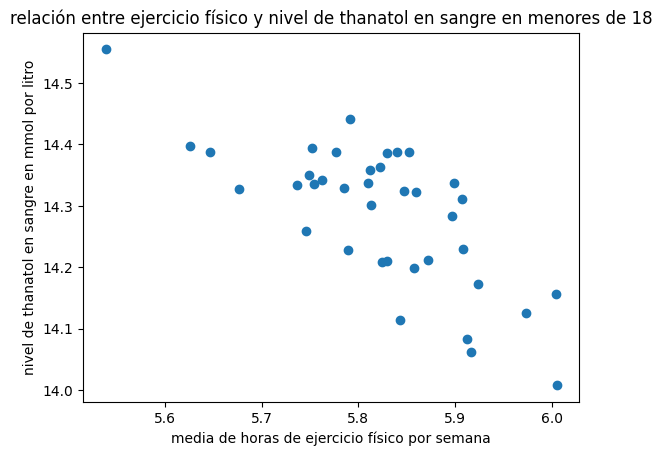

In [7]:
f, ax = pyplot.subplots()
ax.set_title("relación entre ejercicio físico y nivel de thanatol en sangre en menores de 18")
ax.set_xlabel('media de horas de ejercicio físico por semana')
ax.set_ylabel('nivel de thanatol en sangre en mmol por litro')
ax.plot(young_participants['hours_per_week'], young_participants['mmol_per_l'], 'o')

**2. ¿Estás de acuerdo con la Dra. Simpson que hay una correlación fuerte negativa entre ejercicio físico y nivel de thanatol en sangre para menores de 18 años?**

No del todo. Motivos:
- Observando la gráfica anterior se pueden ver ejemplos contradictorios:
    - hay casos donde con ~5.85h de ejercicio el paciente tiene ~14.15mmol de thanatol
    - hay casos donde con ~5,80h de ejercicio el paciente tiene ~14.45mmol de thanatol
- El [Pearson correlation coefficient](https://en.wikipedia.org/wiki/Pearson_correlation_coefficient) entre las dos variables `hours_per_week` y `mmol_per_l` es `-0.7260`. Si fuese `1` entonces probablemente los datos darían la razón a la Dra. Simpson.


In [8]:
young_participants.corr(method='pearson')

,age,hours_per_week,mmol_per_l
age,1.000000,0.437725,0.300464
hours_per_week,0.437725,1.000000,-0.726030
mmol_per_l,0.300464,-0.726030,1.000000


**3. ¿Crees que es buena idea recomendar a los pacientes de la Dra. Simpson que empiecen a hacer ejercicio inmediatamente?**

No, porque no sabemos si realmente es la cantidad de ejercicio la que causa que el nivel de thanatol disminuye en jovenes de menos de 18: https://en.wikipedia.org/wiki/Correlation_does_not_imply_causation

## Ejercicio 6

> La Dra. Nemtsova estaba en la mesa de al lado y ha escuchado las conversaciones tanto con la Dra. Sánchez como con la Dra. Simpson.
>
> Además la Dra. Nemtsova está preocupada por la salud de sus padres, que tienen 50 y 52 años.
> 
> Después de escuchar los argumentos de la Dra. Sánchez iba a recomendarles que dejasen de hacer ejercicio inmediatamente, pero al escuchar a la Dra. Simpson decidió usar su metodología y restringir su análisis a la franja de edad de 50 a 52 años: ha descubierto que en esta franja de edad hay una correlación negativa muy fuerte entre ejercicio físico y nivel de thanatol en sangre. Ahora no sabe que recomendar.
> 
> La Dra. Nemtsova es una científica responsable; se ha dado cuenta de que hay algo que no entiende y ha empezado a probar cosas a ver si encuentra una explicación. Ha decidido visualizar a la vez los datos disponibles a ver si algo le salta a la vista, y ha pintado:
>
> * el conjunto de datos total
> * el conjunto de datos de 16-18 años
> * el conjunto de datos de 50-52 años
>
> En efecto, parece obvio a simple vista que hay una correlación positiva entre ejercicio y thanatol en el conjunto de datos total, y correlaciones negativas en los conjuntos de datos de 16-18 y 50-52.
>
> 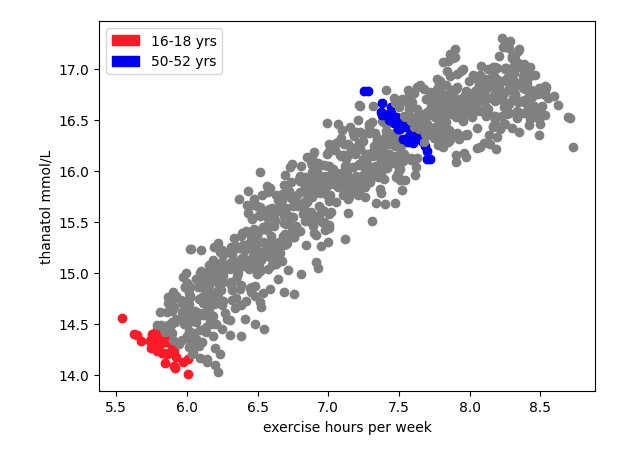
>

**1. Crea una visualización idéntica usando tus herramientas para confirmar que la Dra. Nemtsova no se ha equivocado al crear la visualización**

In [9]:
parents_like_participants = all[(all.age >= 50) & (all.age <= 52)]
parents_like_participants

,age,hours_per_week,mmol_per_l
630,50.020534,7.382237,16.546568
631,50.072553,7.527788,16.309963
632,50.127310,7.373883,16.574302
633,50.182067,7.255418,16.779519
634,50.236824,7.428519,16.496558
635,50.288843,7.393267,16.562471
636,50.343600,7.565775,16.280167
637,50.398357,7.493190,16.408640
638,50.453114,7.461899,16.467936
639,50.505133,7.441523,16.508957


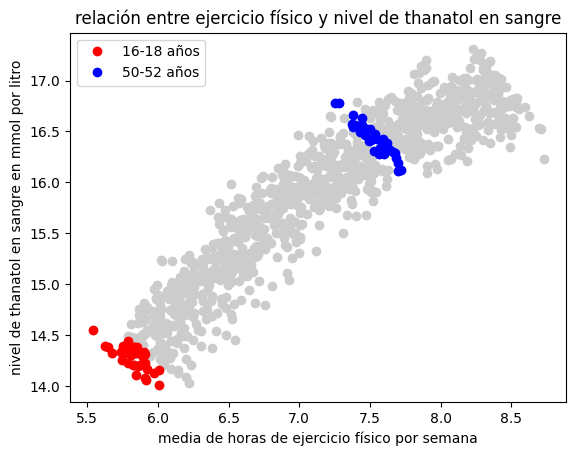

In [10]:
f, ax = pyplot.subplots()
ax.set_title("relación entre ejercicio físico y nivel de thanatol en sangre")
ax.set_xlabel('media de horas de ejercicio físico por semana')
ax.set_ylabel('nivel de thanatol en sangre en mmol por litro')
ax.plot(all['hours_per_week'], all['mmol_per_l'], color='#ccc', marker='o', linewidth=0)
ax.plot(young_participants['hours_per_week'], young_participants['mmol_per_l'], color='red', marker='o', linewidth=0, label='16-18 años')
ax.plot(parents_like_participants['hours_per_week'], parents_like_participants['mmol_per_l'], color='blue', marker='o', linewidth=0, label='50-52 años')
ax.legend()

**2. Si te fijas en cualquier franja de edad de 2 años eg. 20-22, ¿siempre se observa una correlación negativa?**
Sí, ver gráfica abajo:

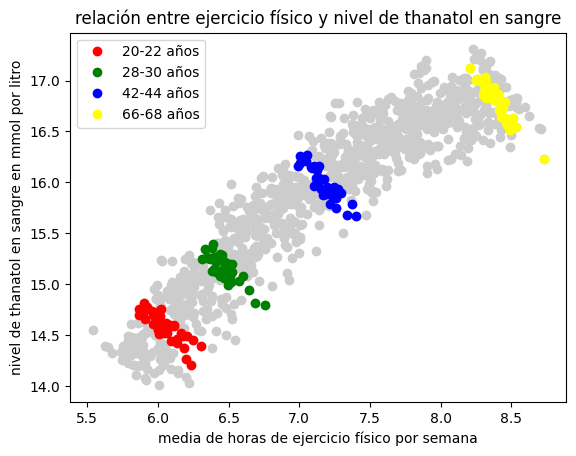

In [11]:
participants_20_22 = all[(all.age >= 20) & (all.age <= 22)]
participants_28_30 = all[(all.age >= 28) & (all.age <= 30)]
participants_42_44 = all[(all.age >= 42) & (all.age <= 44)]
participants_66_68 = all[(all.age >= 66) & (all.age <= 68)]

f, ax = pyplot.subplots()
ax.set_title("relación entre ejercicio físico y nivel de thanatol en sangre")
ax.set_xlabel('media de horas de ejercicio físico por semana')
ax.set_ylabel('nivel de thanatol en sangre en mmol por litro')
ax.plot(all['hours_per_week'], all['mmol_per_l'], color='#ccc', marker='o', linewidth=0)
ax.plot(participants_20_22['hours_per_week'], participants_20_22['mmol_per_l'], color='red', marker='o', linewidth=0, label='20-22 años')
ax.plot(participants_28_30['hours_per_week'], participants_28_30['mmol_per_l'], color='green', marker='o', linewidth=0, label='28-30 años')
ax.plot(participants_42_44['hours_per_week'], participants_42_44['mmol_per_l'], color='blue', marker='o', linewidth=0, label='42-44 años')
ax.plot(participants_66_68['hours_per_week'], participants_66_68['mmol_per_l'], color='yellow', marker='o', linewidth=0, label='66-68 años')
ax.legend()

**3. A la Dra. Simpson le suena que un antepasado suyo, un estadístico inglés, observó un fenómeno similar y publicó al respecto. ¿Puedes encontrar el nombre del fenómeno que estamos observando?**

https://en.wikipedia.org/wiki/Simpson%27s_paradox

**4. ¿Deberíamos recomendar a la gente que haga menos ejercicio? ¿Más ejercicio? ¿Otra cosa?**

No deberiamos recomendar nada porque con los datos que tenemos sólo podemos observar la correlación, pero no sabemos que es mejor.